# MSCS 634 - Lab Assignment 4

**Name:** Chun-Shuo Sheu
**Course:** MSCS 634 - Big Data & Data Mining
**Lab Assignment:** Lab 4 - Regression Analysis with Regularization Techniques on the Diabetes Dataset

## Overview
In this lab, we explore several regression techniques using the Diabetes Dataset from the `sklearn` Python library. We build a **Simple Linear Regression** model, a **Multiple Regression** model, and **Polynomial Regression** models of increasing degree, and then apply **Ridge** and **Lasso** regularization to control the overfitting that the higher-degree polynomial models introduce.

Every model is evaluated on the same held-out test set with four metrics - **MAE**, **MSE**, **RMSE**, and **R2** - so the results are directly comparable. We also visualize predictions, the bias-variance trade-off across polynomial degrees, and how the regularization strength `alpha` reshapes the coefficients.

## Step 1: Data Preparation

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings('ignore', category=ConvergenceWarning)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [8]:
# Load the Diabetes dataset
diabetes = load_diabetes()
X = diabetes.data
y = diabetes.target
feature_names = diabetes.feature_names

df = pd.DataFrame(X, columns=feature_names)
df['target'] = y

print(f"Dataset shape: {df.shape}")
print(f"Number of features: {len(feature_names)}")
print(f"Feature names: {list(feature_names)}")
df.head()

Dataset shape: (442, 11)
Number of features: 10
Feature names: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [9]:
# Feature descriptive statistics
print("Feature descriptive statistics:")
df[feature_names].describe()

Feature descriptive statistics:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
count,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02
mean,-2.511817e-19,1.230790e-17,-2.245564e-16,-4.797570e-17,-1.381499e-17,3.918434e-17,-5.777179e-18,-9.042540e-18,9.268604e-17,1.130318e-17
std,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02
min,-1.072256e-01,-4.464164e-02,-9.027530e-02,-1.123988e-01,-1.267807e-01,-1.156131e-01,-1.023071e-01,-7.639450e-02,-1.260971e-01,-1.377672e-01
25%,-3.729927e-02,-4.464164e-02,-3.422907e-02,-3.665608e-02,-3.424784e-02,-3.035840e-02,-3.511716e-02,-3.949338e-02,-3.324559e-02,-3.317903e-02
50%,5.383060e-03,-4.464164e-02,-7.283766e-03,-5.670422e-03,-4.320866e-03,-3.819065e-03,-6.584468e-03,-2.592262e-03,-1.947171e-03,-1.077698e-03
75%,3.807591e-02,5.068012e-02,3.124802e-02,3.564379e-02,2.835801e-02,2.984439e-02,2.931150e-02,3.430886e-02,3.243232e-02,2.791705e-02
max,1.107267e-01,5.068012e-02,1.705552e-01,1.320436e-01,1.539137e-01,1.987880e-01,1.811791e-01,1.852344e-01,1.335973e-01,1.356118e-01


In [10]:
# Target descriptive statistics
print("Target (disease progression one year after baseline):")
print(df['target'].describe())

Target (disease progression one year after baseline):
count    442.000000
mean     152.133484
std       77.093005
min       25.000000
25%       87.000000
50%      140.500000
75%      211.500000
max      346.000000
Name: target, dtype: float64


In [11]:
# Data cleaning: check for missing values and duplicates
print("Missing values per column:")
print(df.isnull().sum())
print(f"\nTotal missing values: {df.isnull().sum().sum()}")
print(f"Duplicate rows: {df.duplicated().sum()}")
print(f"Data types: {df.dtypes.unique()}")

Missing values per column:
age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
target    0
dtype: int64

Total missing values: 0
Duplicate rows: 0
Data types: [dtype('float64')]


The Diabetes dataset ships pre-cleaned: there are no missing values, no duplicate rows, and every column is numeric. The 10 predictors have also already been mean-centered and scaled by `n_samples * std`, so each feature has mean ~0 and the same L2 norm. No further imputation or cleaning is required - but note that the *target* is **not** scaled, so the error metrics below are in the original disease-progression units.

In [12]:
# Verify the built-in scaling of the predictors
print("Feature means (approx 0):", X.mean(axis=0).round(6))
print("Feature L2 norms (identical by construction):", np.linalg.norm(X, axis=0).round(6))

Feature means (approx 0): [-0.  0. -0. -0. -0.  0. -0. -0.  0.  0.]
Feature L2 norms (identical by construction): [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


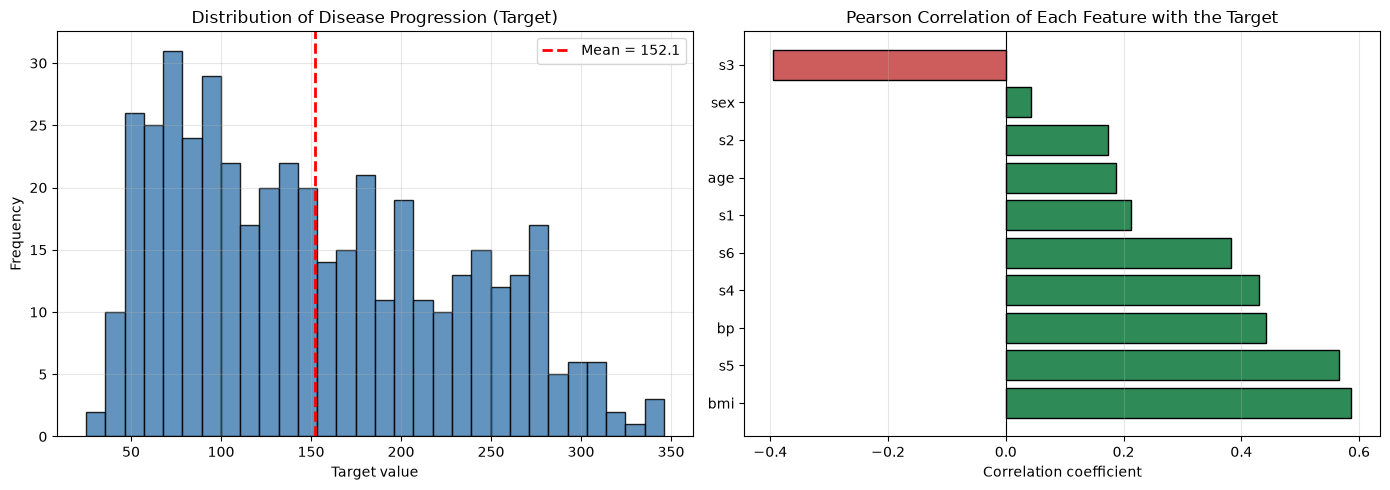

Correlation with target:
bmi    0.5865
s5     0.5659
bp     0.4415
s4     0.4305
s6     0.3825
s1     0.2120
age    0.1879
s2     0.1741
sex    0.0431
s3    -0.3948
dtype: float64


In [13]:
# Distribution of the target and its correlation with each feature
correlations = df[feature_names].corrwith(df['target']).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(y, bins=30, color='steelblue', edgecolor='black', alpha=0.85)
axes[0].axvline(y.mean(), color='red', linestyle='--', linewidth=2, label=f'Mean = {y.mean():.1f}')
axes[0].set_title('Distribution of Disease Progression (Target)')
axes[0].set_xlabel('Target value')
axes[0].set_ylabel('Frequency')
axes[0].legend()
axes[0].grid(alpha=0.3)

colors = ['seagreen' if c > 0 else 'indianred' for c in correlations.values]
axes[1].barh(correlations.index, correlations.values, color=colors, edgecolor='black')
axes[1].axvline(0, color='black', linewidth=0.8)
axes[1].set_title('Pearson Correlation of Each Feature with the Target')
axes[1].set_xlabel('Correlation coefficient')
axes[1].grid(alpha=0.3, axis='x')

plt.tight_layout()
plt.savefig('data_exploration.png', dpi=120, bbox_inches='tight')
plt.show()

print("Correlation with target:")
print(correlations.round(4))

In [14]:
# Shared 80/20 train-test split used by every model in this lab
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Test set:     {X_test.shape[0]} samples")

Training set: 353 samples
Test set:     89 samples


In [15]:
def evaluate(name, y_true, y_pred):
    """Compute MAE, MSE, RMSE and R2 for a set of predictions."""
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    print(f"{name}")
    print(f"  MAE : {mae:.4f}")
    print(f"  MSE : {mse:.4f}")
    print(f"  RMSE: {rmse:.4f}")
    print(f"  R2  : {r2:.4f}")
    return {'Model': name, 'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'R2': r2}

# Collects one row per model so we can compare everything in Step 6
results = []

## Step 2: Simple Linear Regression

We start with a single predictor. From the correlation plot above, **BMI** has the strongest linear relationship with disease progression (r = 0.59), so it is the natural choice for the independent variable.

In [16]:
# Simple Linear Regression using BMI only
bmi_idx = feature_names.index('bmi')
X_train_bmi = X_train[:, [bmi_idx]]
X_test_bmi = X_test[:, [bmi_idx]]

simple_lr = LinearRegression()
simple_lr.fit(X_train_bmi, y_train)

y_pred_simple = simple_lr.predict(X_test_bmi)

print(f"Intercept: {simple_lr.intercept_:.4f}")
print(f"Coefficient (bmi): {simple_lr.coef_[0]:.4f}\n")
results.append(evaluate('Simple Linear (bmi)', y_test, y_pred_simple))

Intercept: 152.0034
Coefficient (bmi): 998.5777

Simple Linear (bmi)
  MAE : 52.2600
  MSE : 4061.8259
  RMSE: 63.7325
  R2  : 0.2334


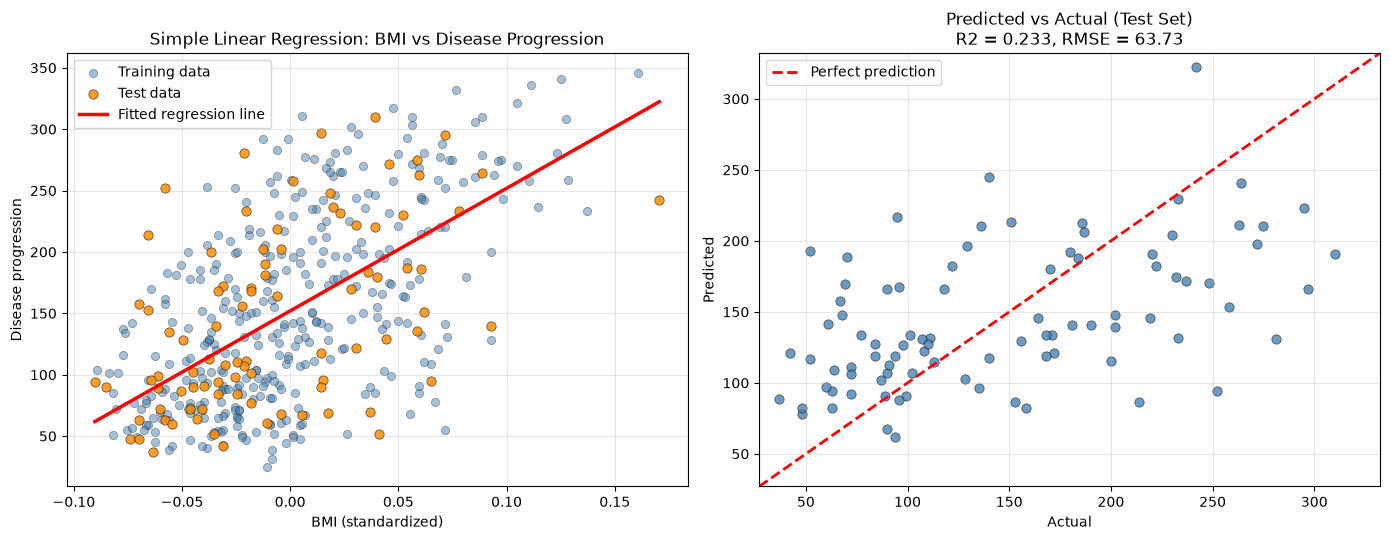

In [17]:
# Visualize the fitted line against the actual data
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

line_x = np.linspace(X[:, bmi_idx].min(), X[:, bmi_idx].max(), 200).reshape(-1, 1)
line_y = simple_lr.predict(line_x)

axes[0].scatter(X_train_bmi, y_train, s=35, alpha=0.5, color='steelblue',
                edgecolors='k', linewidths=0.4, label='Training data')
axes[0].scatter(X_test_bmi, y_test, s=45, alpha=0.85, color='darkorange',
                edgecolors='k', linewidths=0.4, label='Test data')
axes[0].plot(line_x, line_y, color='red', linewidth=2.5, label='Fitted regression line')
axes[0].set_title('Simple Linear Regression: BMI vs Disease Progression')
axes[0].set_xlabel('BMI (standardized)')
axes[0].set_ylabel('Disease progression')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].scatter(y_test, y_pred_simple, s=45, alpha=0.8, color='steelblue',
                edgecolors='k', linewidths=0.4)
lims = [min(y_test.min(), y_pred_simple.min()) - 10, max(y_test.max(), y_pred_simple.max()) + 10]
axes[1].plot(lims, lims, 'r--', linewidth=2, label='Perfect prediction')
axes[1].set_xlim(lims); axes[1].set_ylim(lims)
axes[1].set_title(f'Predicted vs Actual (Test Set)\nR2 = {results[-1]["R2"]:.3f}, RMSE = {results[-1]["RMSE"]:.2f}')
axes[1].set_xlabel('Actual')
axes[1].set_ylabel('Predicted')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('simple_linear_regression.png', dpi=120, bbox_inches='tight')
plt.show()

A single feature captures the broad upward trend - higher BMI is associated with faster disease progression - but the scatter around the line is very wide. The predicted-vs-actual plot collapses into a narrow band because one predictor cannot produce the full range of target values, which is exactly what a low R2 looks like.

## Step 3: Multiple Regression

Now we use all 10 predictors (age, sex, bmi, bp and the six blood-serum measurements) instead of just one.

In [18]:
# Multiple Regression using all 10 features
multi_lr = LinearRegression()
multi_lr.fit(X_train, y_train)

y_pred_multi = multi_lr.predict(X_test)

print(f"Intercept: {multi_lr.intercept_:.4f}\n")
results.append(evaluate('Multiple Linear (10 features)', y_test, y_pred_multi))

Intercept: 151.3456

Multiple Linear (10 features)
  MAE : 42.7941
  MSE : 2900.1936
  RMSE: 53.8534
  R2  : 0.4526


In [19]:
# Inspect the learned coefficients
coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': multi_lr.coef_
}).sort_values('Coefficient', key=abs, ascending=False)

print("Coefficients ordered by magnitude:")
coef_df

Coefficients ordered by magnitude:


,Feature,Coefficient
4,s1,-931.488846
8,s5,736.198859
2,bmi,542.428759
5,s2,518.062277
3,bp,347.703844
7,s4,275.317902
1,sex,-241.964362
6,s3,163.419983
9,s6,48.670657
0,age,37.904021


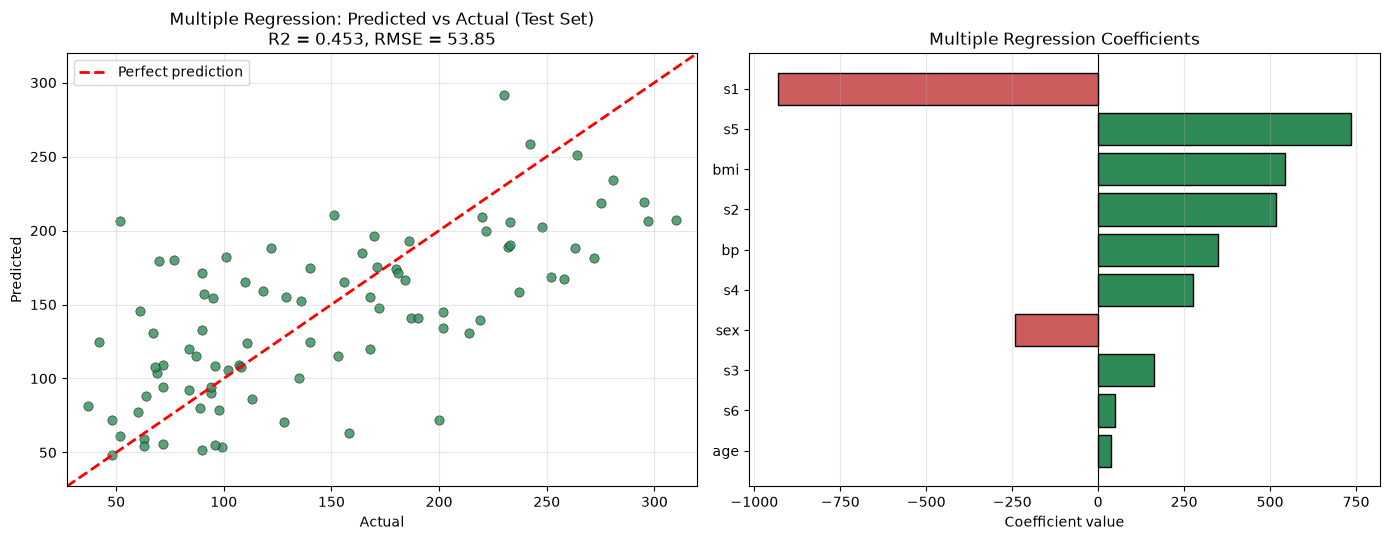

In [20]:
# Visualize predictions and coefficients
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

axes[0].scatter(y_test, y_pred_multi, s=45, alpha=0.8, color='seagreen',
                edgecolors='k', linewidths=0.4)
lims = [min(y_test.min(), y_pred_multi.min()) - 10, max(y_test.max(), y_pred_multi.max()) + 10]
axes[0].plot(lims, lims, 'r--', linewidth=2, label='Perfect prediction')
axes[0].set_xlim(lims); axes[0].set_ylim(lims)
axes[0].set_title(f'Multiple Regression: Predicted vs Actual (Test Set)\nR2 = {results[-1]["R2"]:.3f}, RMSE = {results[-1]["RMSE"]:.2f}')
axes[0].set_xlabel('Actual')
axes[0].set_ylabel('Predicted')
axes[0].legend()
axes[0].grid(alpha=0.3)

order = coef_df.iloc[::-1]
bar_colors = ['seagreen' if c > 0 else 'indianred' for c in order['Coefficient']]
axes[1].barh(order['Feature'], order['Coefficient'], color=bar_colors, edgecolor='black')
axes[1].axvline(0, color='black', linewidth=0.8)
axes[1].set_title('Multiple Regression Coefficients')
axes[1].set_xlabel('Coefficient value')
axes[1].grid(alpha=0.3, axis='x')

plt.tight_layout()
plt.savefig('multiple_regression.png', dpi=120, bbox_inches='tight')
plt.show()

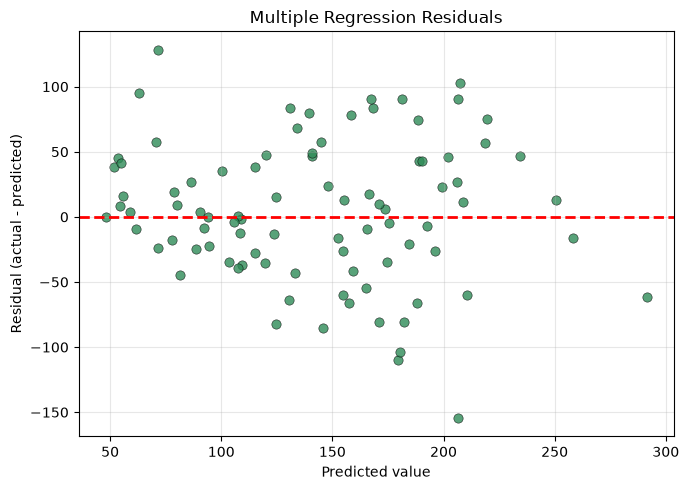

Mean residual: 3.9128
Std of residuals: 53.7111


In [21]:
# Residual plot - a quick check of the linear-model assumptions
residuals = y_test - y_pred_multi

plt.figure(figsize=(7, 5))
plt.scatter(y_pred_multi, residuals, s=45, alpha=0.8, color='seagreen',
            edgecolors='k', linewidths=0.4)
plt.axhline(0, color='red', linestyle='--', linewidth=2)
plt.title('Multiple Regression Residuals')
plt.xlabel('Predicted value')
plt.ylabel('Residual (actual - predicted)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('residuals.png', dpi=120, bbox_inches='tight')
plt.show()

print(f"Mean residual: {residuals.mean():.4f}")
print(f"Std of residuals: {residuals.std():.4f}")

Moving from one feature to ten roughly doubles the explained variance (R2 0.23 -> 0.45) and cuts RMSE by about 10 units. The predicted-vs-actual points now spread across a much wider range and hug the diagonal far more closely.

The coefficient plot holds a surprise: the single largest weight belongs to `s1` at roughly **-931**, even though `s1` has only a weak *positive* correlation with the target (r = 0.21). It is paired against `s5` (+736) and `s2` (+518). This sign flip is a classic symptom of **multicollinearity** - the serum measurements `s1`...`s6` are chemically related, so the model plays them against each other to cancel out shared variance. Individual coefficients become large and unstable even though their combined prediction is fine. `bmi` (+542) and `bp` (+348) behave more sensibly and match their raw correlations.

The residuals are centered on zero with no obvious funnel shape, so the constant-variance assumption is reasonable, though the slight downward tilt at the extremes hints that the model over-predicts for low-progression patients and under-predicts for high-progression ones.

## Step 4: Polynomial Regression

Polynomial regression extends linear regression by adding powers and interaction terms of the original features. Because the model is still linear *in its coefficients*, we can reuse `LinearRegression` - we simply expand the design matrix with `PolynomialFeatures` first.

We sweep degrees 1 through 5 and track **both** training and test error. This is the clearest way to see the bias-variance trade-off: underfitting shows up as high error on both sets, overfitting as low training error paired with exploding test error.

In [22]:
# Sweep polynomial degrees 1-5 on all 10 features
degrees = [1, 2, 3, 4, 5]
poly_records = []
poly_models = {}

for d in degrees:
    model = make_pipeline(
        PolynomialFeatures(degree=d, include_bias=False),
        StandardScaler(),
        LinearRegression()
    )
    model.fit(X_train, y_train)
    poly_models[d] = model

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    n_features = model.named_steps['polynomialfeatures'].n_output_features_
    poly_records.append({
        'Degree': d,
        'N Features': n_features,
        'Train RMSE': np.sqrt(mean_squared_error(y_train, train_pred)),
        'Test RMSE': np.sqrt(mean_squared_error(y_test, test_pred)),
        'Train R2': r2_score(y_train, train_pred),
        'Test R2': r2_score(y_test, test_pred),
    })

poly_df = pd.DataFrame(poly_records)
print("Polynomial degree sweep (n_train = %d samples):" % X_train.shape[0])
poly_df.round(4)

Polynomial degree sweep (n_train = 353 samples):


,Degree,N Features,Train RMSE,Test RMSE,Train R2,Test R2
0,1,10,53.5588,53.8534,0.5279,0.4526
1,2,65,48.9197,55.6420,0.6062,0.4156
2,3,285,27.3789,278.9423,0.8766,-13.6860
3,4,1000,0.0000,422.9767,1.0000,-32.7682
4,5,3002,0.0000,261.1093,1.0000,-11.8683


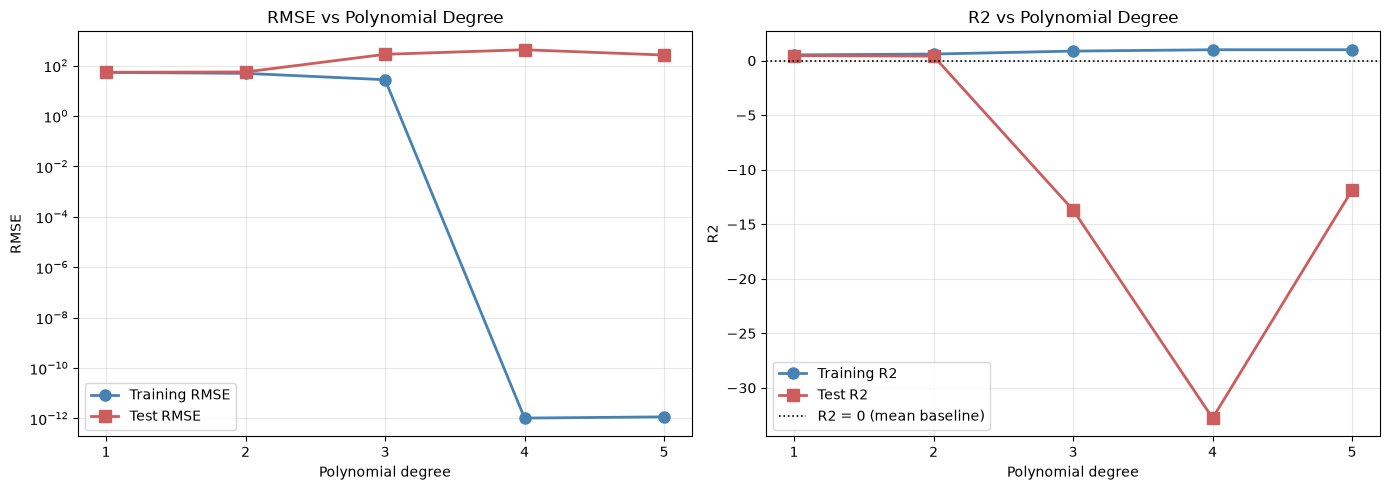

In [23]:
# Visualize the bias-variance trade-off across polynomial degrees
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(poly_df['Degree'], poly_df['Train RMSE'], 'o-', linewidth=2,
             markersize=8, label='Training RMSE', color='steelblue')
axes[0].plot(poly_df['Degree'], poly_df['Test RMSE'], 's-', linewidth=2,
             markersize=8, label='Test RMSE', color='indianred')
axes[0].set_title('RMSE vs Polynomial Degree')
axes[0].set_xlabel('Polynomial degree')
axes[0].set_ylabel('RMSE')
axes[0].set_yscale('log')
axes[0].set_xticks(degrees)
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(poly_df['Degree'], poly_df['Train R2'], 'o-', linewidth=2,
             markersize=8, label='Training R2', color='steelblue')
axes[1].plot(poly_df['Degree'], poly_df['Test R2'], 's-', linewidth=2,
             markersize=8, label='Test R2', color='indianred')
axes[1].axhline(0, color='black', linestyle=':', linewidth=1.2, label='R2 = 0 (mean baseline)')
axes[1].set_title('R2 vs Polynomial Degree')
axes[1].set_xlabel('Polynomial degree')
axes[1].set_ylabel('R2')
axes[1].set_xticks(degrees)
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('polynomial_degree_analysis.png', dpi=120, bbox_inches='tight')
plt.show()

In [24]:
# Record the degree-2 and degree-3 polynomial models for the final comparison
results.append(evaluate('Polynomial deg=2 (unregularized)', y_test, poly_models[2].predict(X_test)))
print()
results.append(evaluate('Polynomial deg=3 (unregularized)', y_test, poly_models[3].predict(X_test)))

Polynomial deg=2 (unregularized)
  MAE : 43.5817
  MSE : 3096.0283
  RMSE: 55.6420
  R2  : 0.4156

Polynomial deg=3 (unregularized)
  MAE : 161.1896
  MSE : 77808.8016
  RMSE: 278.9423
  R2  : -13.6860


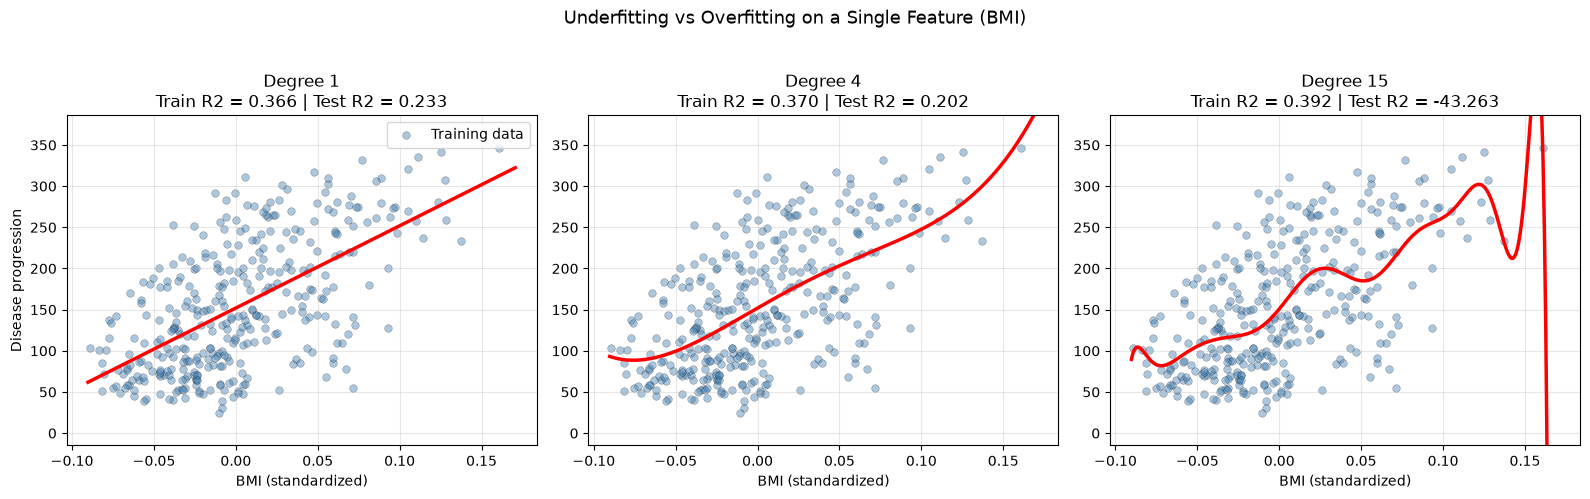

In [25]:
# A 1-D view of underfitting vs overfitting using BMI alone
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
line_x = np.linspace(X[:, bmi_idx].min(), X[:, bmi_idx].max(), 300).reshape(-1, 1)

for ax, d in zip(axes, [1, 4, 15]):
    m = make_pipeline(PolynomialFeatures(degree=d, include_bias=False),
                      StandardScaler(), LinearRegression())
    m.fit(X_train_bmi, y_train)
    test_r2 = r2_score(y_test, m.predict(X_test_bmi))
    train_r2 = r2_score(y_train, m.predict(X_train_bmi))

    ax.scatter(X_train_bmi, y_train, s=30, alpha=0.45, color='steelblue',
               edgecolors='k', linewidths=0.3, label='Training data')
    ax.plot(line_x, m.predict(line_x), color='red', linewidth=2.5)
    ax.set_ylim(y.min() - 40, y.max() + 40)
    ax.set_title(f'Degree {d}\nTrain R2 = {train_r2:.3f} | Test R2 = {test_r2:.3f}')
    ax.set_xlabel('BMI (standardized)')
    ax.grid(alpha=0.3)

axes[0].set_ylabel('Disease progression')
axes[0].legend()
plt.suptitle('Underfitting vs Overfitting on a Single Feature (BMI)', y=1.03, fontsize=13)
plt.tight_layout()
plt.savefig('polynomial_fit_bmi.png', dpi=120, bbox_inches='tight')
plt.show()

### How polynomial degree affects overfitting and underfitting

On this dataset the test error never improves with degree - it is already at its minimum at degree 1 and degrades from there, gently at first and then catastrophically:

- **Degree 1** (10 features) is the plain multiple regression: train R2 = 0.528, test R2 = 0.453. The two are close, which means the model is not memorizing the data - if anything it is slightly **underfitting**, since it can only represent additive linear effects.
- **Degree 2** (65 features) fits the training set noticeably better (train R2 0.528 -> 0.606) but the test error gets *worse* (RMSE 53.9 -> 55.6). The gap between train and test R2 more than doubles. The extra interaction terms are already picking up noise - mild but real overfitting.
- **Degree 3** (285 features) has nearly as many parameters as the 353 training samples. Train R2 climbs to 0.877 while test R2 crashes to **-13.7** - the model is now dramatically worse than simply predicting the mean. This is textbook **overfitting**.
- **Degrees 4-5** (1000 and 3002 features) have far more parameters than samples. The fit interpolates the training data *exactly* - train RMSE hits 0.0 and train R2 hits 1.0 - and the test predictions become wild. Note that degree 5's test RMSE (261) happens to be lower than degree 4's (423); this is not a recovery. Once the model interpolates the training set, the fit is determined by the minimum-norm solution rather than by any signal, so the test error at that point is essentially arbitrary noise.

The single-feature plots make the same point visually. Degree 1 is a rigid straight line - high bias, but its test R2 of 0.233 is the best of the three. Degree 4 adds gentle curvature that barely improves the training fit (0.366 -> 0.370) while already costing test accuracy (0.233 -> 0.202). Degree 15 wiggles violently to chase individual training points and shoots off the chart at the right-hand edge where the data thins out; it buys a training R2 of 0.392 at the price of a test R2 of **-43.3**. That edge behavior is the signature of high variance: the fit is dictated by a handful of extreme points rather than by the overall trend.

The takeaway is that raw polynomial expansion adds capacity much faster than it adds useful signal on this dataset. That is precisely the problem regularization is designed to solve.

## Step 5: Regularization with Ridge and Lasso Regression

Ridge and Lasso both add a penalty on coefficient magnitude to the least-squares objective:

- **Ridge (L2):** minimize `||y - Xw||^2 + alpha * ||w||^2` - shrinks all coefficients smoothly toward zero but never exactly to zero.
- **Lasso (L1):** minimize `||y - Xw||^2 / (2n) + alpha * ||w||_1` - can drive coefficients *exactly* to zero, so it performs automatic feature selection.

We apply both to the **degree-2 polynomial features**, since that is where the unregularized model started to overfit. Features are standardized before the penalty is applied, otherwise the penalty would be applied unfairly across terms with different scales.

In [26]:
# Build the degree-2 polynomial design matrix (standardized)
poly2 = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly2 = poly2.fit_transform(X_train)
X_test_poly2 = poly2.transform(X_test)

scaler_poly2 = StandardScaler()
X_train_poly2s = scaler_poly2.fit_transform(X_train_poly2)
X_test_poly2s = scaler_poly2.transform(X_test_poly2)

poly2_names = poly2.get_feature_names_out(feature_names)
print(f"Degree-2 design matrix: {X_train_poly2s.shape[1]} features from {X_train_poly2s.shape[0]} training samples")

Degree-2 design matrix: 65 features from 353 training samples


In [27]:
# Sweep alpha for Ridge and Lasso, tracking train/test error and coefficient size
alphas = np.logspace(-4, 4, 60)

ridge_curve, lasso_curve = [], []
ridge_coef_paths, lasso_coef_paths = [], []

for a in alphas:
    r = Ridge(alpha=a, random_state=RANDOM_STATE)
    r.fit(X_train_poly2s, y_train)
    ridge_curve.append({
        'alpha': a,
        'Train RMSE': np.sqrt(mean_squared_error(y_train, r.predict(X_train_poly2s))),
        'Test RMSE': np.sqrt(mean_squared_error(y_test, r.predict(X_test_poly2s))),
        'Test R2': r2_score(y_test, r.predict(X_test_poly2s)),
        'Nonzero coefs': int(np.sum(np.abs(r.coef_) > 1e-8)),
    })
    ridge_coef_paths.append(r.coef_)

    l = Lasso(alpha=a, max_iter=100000, random_state=RANDOM_STATE)
    l.fit(X_train_poly2s, y_train)
    lasso_curve.append({
        'alpha': a,
        'Train RMSE': np.sqrt(mean_squared_error(y_train, l.predict(X_train_poly2s))),
        'Test RMSE': np.sqrt(mean_squared_error(y_test, l.predict(X_test_poly2s))),
        'Test R2': r2_score(y_test, l.predict(X_test_poly2s)),
        'Nonzero coefs': int(np.sum(np.abs(l.coef_) > 1e-8)),
    })
    lasso_coef_paths.append(l.coef_)

ridge_curve = pd.DataFrame(ridge_curve)
lasso_curve = pd.DataFrame(lasso_curve)
ridge_coef_paths = np.array(ridge_coef_paths)
lasso_coef_paths = np.array(lasso_coef_paths)

print("Ridge - best test RMSE at alpha = %.4f (RMSE = %.3f)" % (
    ridge_curve.loc[ridge_curve['Test RMSE'].idxmin(), 'alpha'],
    ridge_curve['Test RMSE'].min()))
print("Lasso - best test RMSE at alpha = %.4f (RMSE = %.3f)" % (
    lasso_curve.loc[lasso_curve['Test RMSE'].idxmin(), 'alpha'],
    lasso_curve['Test RMSE'].min()))

Ridge - best test RMSE at alpha = 26.5295 (RMSE = 50.921)
Lasso - best test RMSE at alpha = 2.1826 (RMSE = 50.477)


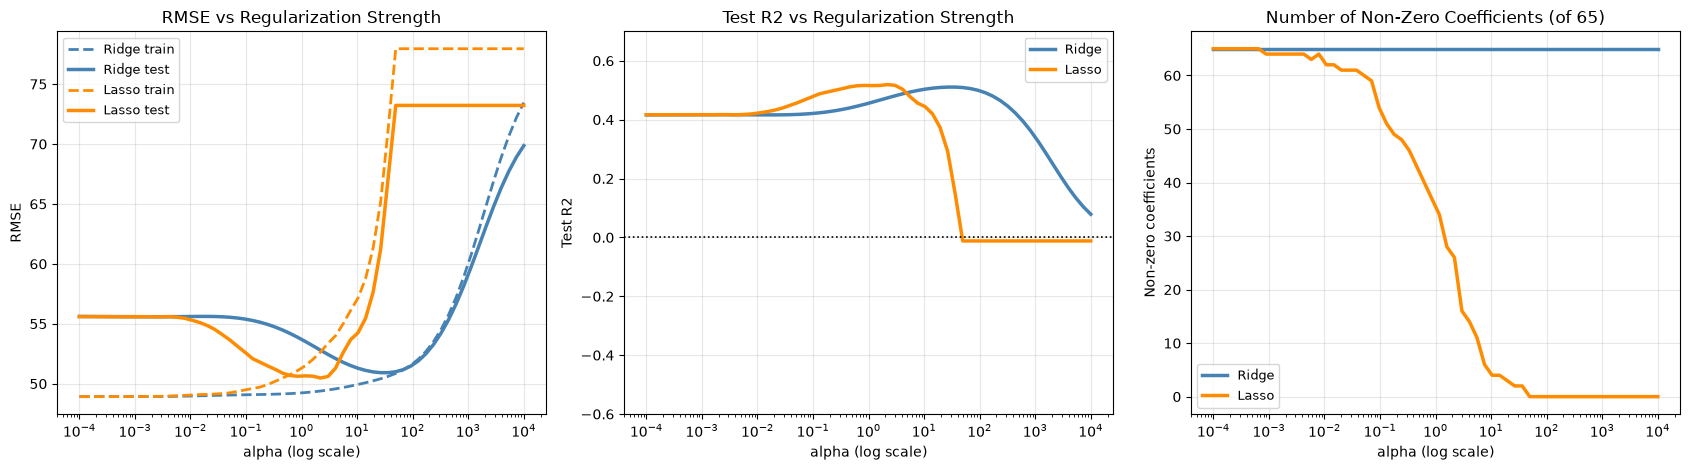

In [28]:
# How alpha influences error and model complexity
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

axes[0].semilogx(ridge_curve['alpha'], ridge_curve['Train RMSE'], '--',
                 linewidth=2, color='steelblue', label='Ridge train')
axes[0].semilogx(ridge_curve['alpha'], ridge_curve['Test RMSE'], '-',
                 linewidth=2.5, color='steelblue', label='Ridge test')
axes[0].semilogx(lasso_curve['alpha'], lasso_curve['Train RMSE'], '--',
                 linewidth=2, color='darkorange', label='Lasso train')
axes[0].semilogx(lasso_curve['alpha'], lasso_curve['Test RMSE'], '-',
                 linewidth=2.5, color='darkorange', label='Lasso test')
axes[0].set_title('RMSE vs Regularization Strength')
axes[0].set_xlabel('alpha (log scale)')
axes[0].set_ylabel('RMSE')
axes[0].legend(fontsize=9)
axes[0].grid(alpha=0.3)

axes[1].semilogx(ridge_curve['alpha'], ridge_curve['Test R2'], linewidth=2.5,
                 color='steelblue', label='Ridge')
axes[1].semilogx(lasso_curve['alpha'], lasso_curve['Test R2'], linewidth=2.5,
                 color='darkorange', label='Lasso')
axes[1].axhline(0, color='black', linestyle=':', linewidth=1.2)
axes[1].set_ylim(-0.6, 0.7)
axes[1].set_title('Test R2 vs Regularization Strength')
axes[1].set_xlabel('alpha (log scale)')
axes[1].set_ylabel('Test R2')
axes[1].legend(fontsize=9)
axes[1].grid(alpha=0.3)

axes[2].semilogx(ridge_curve['alpha'], ridge_curve['Nonzero coefs'], linewidth=2.5,
                 color='steelblue', label='Ridge')
axes[2].semilogx(lasso_curve['alpha'], lasso_curve['Nonzero coefs'], linewidth=2.5,
                 color='darkorange', label='Lasso')
axes[2].set_title('Number of Non-Zero Coefficients (of %d)' % X_train_poly2s.shape[1])
axes[2].set_xlabel('alpha (log scale)')
axes[2].set_ylabel('Non-zero coefficients')
axes[2].legend(fontsize=9)
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('regularization_alpha.png', dpi=120, bbox_inches='tight')
plt.show()

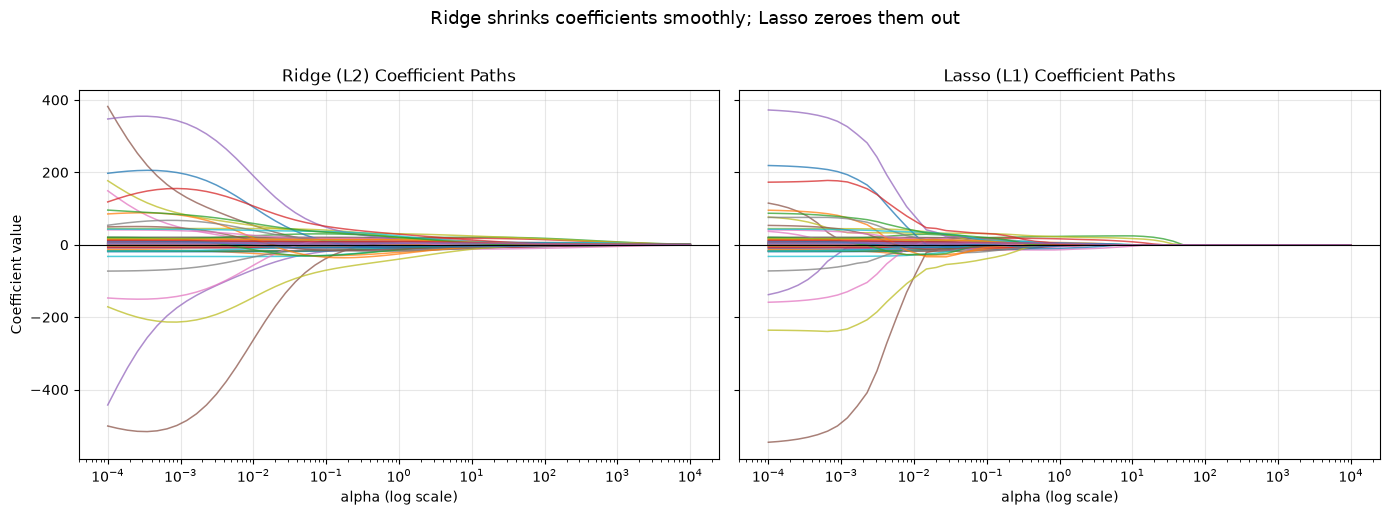

In [29]:
# Coefficient paths - the clearest picture of how Ridge and Lasso differ
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for j in range(ridge_coef_paths.shape[1]):
    axes[0].semilogx(alphas, ridge_coef_paths[:, j], linewidth=1.1, alpha=0.75)
    axes[1].semilogx(alphas, lasso_coef_paths[:, j], linewidth=1.1, alpha=0.75)

axes[0].axhline(0, color='black', linewidth=0.8)
axes[0].set_title('Ridge (L2) Coefficient Paths')
axes[0].set_xlabel('alpha (log scale)')
axes[0].set_ylabel('Coefficient value')
axes[0].grid(alpha=0.3)

axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].set_title('Lasso (L1) Coefficient Paths')
axes[1].set_xlabel('alpha (log scale)')
axes[1].grid(alpha=0.3)

plt.suptitle('Ridge shrinks coefficients smoothly; Lasso zeroes them out', y=1.02, fontsize=13)
plt.tight_layout()
plt.savefig('coefficient_paths.png', dpi=120, bbox_inches='tight')
plt.show()

### How the alpha parameter influences the models

`alpha` controls the trade-off between fitting the training data and keeping the coefficients small:

- **alpha -> 0**: the penalty vanishes and both models converge to ordinary least squares on the 65 polynomial features. Training error is at its minimum, coefficients are large, and test error is poor - the overfitting regime on the left of the plots.
- **Moderate alpha**: coefficients shrink, variance drops faster than bias rises, and test error reaches its minimum. This is the sweet spot.
- **alpha -> infinity**: the penalty dominates, all coefficients are crushed toward zero, and the model degenerates into predicting the training mean. Test R2 flattens out at ~0 - the underfitting regime on the right.

The **coefficient path plots** show the structural difference between the two penalties. Ridge pulls every coefficient smoothly toward zero but keeps all 65 of them alive at any finite alpha. Lasso instead knocks coefficients out one at a time; by the time alpha reaches ~10 only a handful of features survive. That is why the "non-zero coefficients" panel is a flat line at 65 for Ridge and a staircase down to 0 for Lasso.

In [30]:
# Select alpha honestly, via 5-fold cross-validation on the TRAINING set only
ridge_grid = GridSearchCV(Ridge(random_state=RANDOM_STATE), {'alpha': alphas},
                          scoring='neg_root_mean_squared_error', cv=5)
ridge_grid.fit(X_train_poly2s, y_train)

lasso_grid = GridSearchCV(Lasso(max_iter=100000, random_state=RANDOM_STATE), {'alpha': alphas},
                          scoring='neg_root_mean_squared_error', cv=5)
lasso_grid.fit(X_train_poly2s, y_train)

best_ridge = ridge_grid.best_estimator_
best_lasso = lasso_grid.best_estimator_

print(f"Ridge best alpha (5-fold CV): {ridge_grid.best_params_['alpha']:.4f}  "
      f"| CV RMSE = {-ridge_grid.best_score_:.3f}")
print(f"Lasso best alpha (5-fold CV): {lasso_grid.best_params_['alpha']:.4f}  "
      f"| CV RMSE = {-lasso_grid.best_score_:.3f}")

Ridge best alpha (5-fold CV): 92.4915  | CV RMSE = 57.529
Lasso best alpha (5-fold CV): 2.9825  | CV RMSE = 56.822


In [38]:
# Evaluate the tuned regularized models on the held-out test set
y_pred_ridge = best_ridge.predict(X_test_poly2s)
y_pred_lasso = best_lasso.predict(X_test_poly2s)

results.append(evaluate(f"Ridge deg=2 (alpha={ridge_grid.best_params_['alpha']:.3g})",
                        y_test, y_pred_ridge))
print()
results.append(evaluate(f"Lasso deg=2 (alpha={lasso_grid.best_params_['alpha']:.3g})",
                        y_test, y_pred_lasso))

print(f"\nRidge kept {np.sum(np.abs(best_ridge.coef_) > 1e-8)} / {len(best_ridge.coef_)} non-zero coefficients")
print(f"Lasso kept {np.sum(np.abs(best_lasso.coef_) > 1e-8)} / {len(best_lasso.coef_)} non-zero coefficients")

Ridge deg=2 (alpha=92.5)
  MAE : 41.4136
  MSE : 2649.3549
  RMSE: 51.4719
  R2  : 0.4999

Lasso deg=2 (alpha=2.98)
  MAE : 41.1625
  MSE : 2560.4197
  RMSE: 50.6006
  R2  : 0.5167

Ridge kept 65 / 65 non-zero coefficients
Lasso kept 16 / 65 non-zero coefficients


In [39]:
# Which polynomial terms did Lasso keep?
selected = pd.DataFrame({
    'Feature': poly2_names,
    'Lasso Coefficient': best_lasso.coef_,
    'Ridge Coefficient': best_ridge.coef_,
})
selected = selected[np.abs(selected['Lasso Coefficient']) > 1e-8]
selected = selected.reindex(selected['Lasso Coefficient'].abs().sort_values(ascending=False).index)

print("Features surviving Lasso selection:")
selected.round(4)

Features surviving Lasso selection:


,Feature,Lasso Coefficient,Ridge Coefficient
2,bmi,24.0558,18.0884
8,s5,19.6094,16.5065
3,bp,13.6199,14.3038
6,s3,-10.2721,-9.6404
20,sex^2,-5.7598,-4.6901
11,age sex,4.1751,4.9362
29,bmi^2,3.2923,4.7895
30,bmi bp,2.8132,5.1369
64,s6^2,2.0101,2.4554
18,age s5,1.2475,3.9689


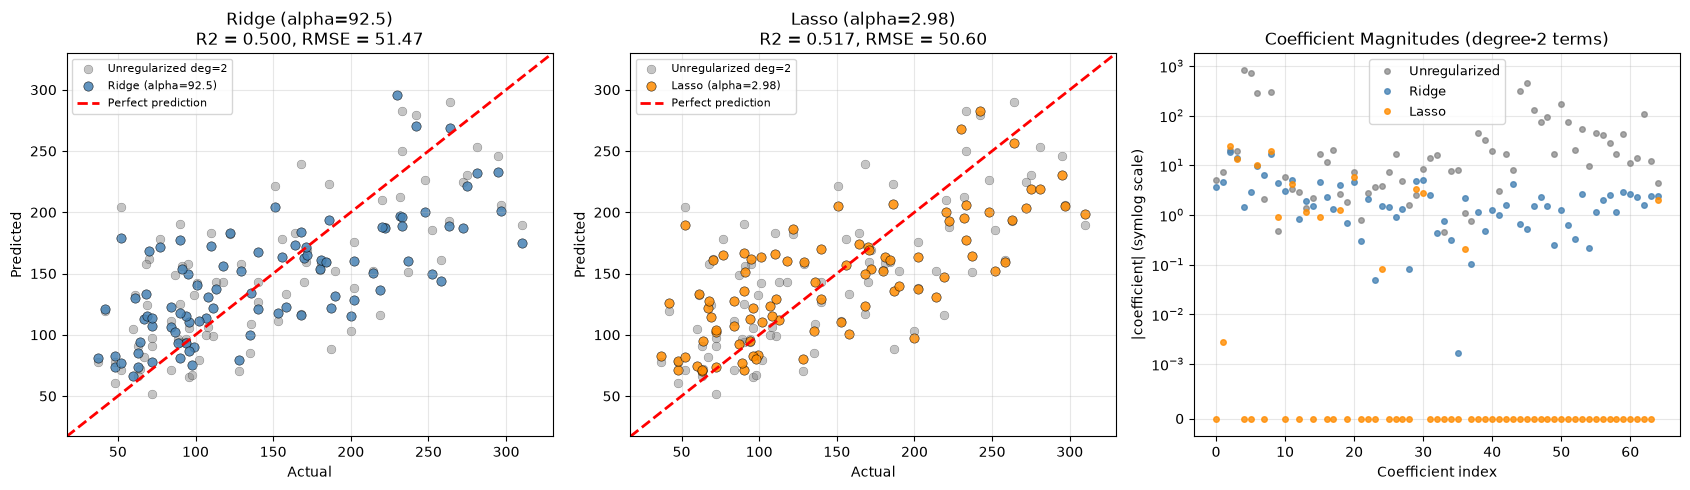

In [40]:
# Ridge vs Lasso predictions side by side, plus their coefficient magnitudes
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

unreg_poly2_pred = poly_models[2].predict(X_test)
lims = [y_test.min() - 20, y_test.max() + 20]

for ax, preds, name, color in zip(
        axes[:2],
        [y_pred_ridge, y_pred_lasso],
        [f"Ridge (alpha={ridge_grid.best_params_['alpha']:.3g})",
         f"Lasso (alpha={lasso_grid.best_params_['alpha']:.3g})"],
        ['steelblue', 'darkorange']):
    ax.scatter(y_test, unreg_poly2_pred, s=40, alpha=0.45, color='gray',
               edgecolors='k', linewidths=0.3, label='Unregularized deg=2')
    ax.scatter(y_test, preds, s=45, alpha=0.85, color=color,
               edgecolors='k', linewidths=0.4, label=name)
    ax.plot(lims, lims, 'r--', linewidth=2, label='Perfect prediction')
    ax.set_xlim(lims); ax.set_ylim(lims)
    ax.set_title(f'{name}\nR2 = {r2_score(y_test, preds):.3f}, '
                 f'RMSE = {np.sqrt(mean_squared_error(y_test, preds)):.2f}')
    ax.set_xlabel('Actual')
    ax.set_ylabel('Predicted')
    ax.legend(fontsize=8, loc='upper left')
    ax.grid(alpha=0.3)

unreg_coefs = poly_models[2].named_steps['linearregression'].coef_
idx = np.arange(len(unreg_coefs))
axes[2].plot(idx, np.abs(unreg_coefs), 'o', markersize=4, alpha=0.7,
             color='gray', label='Unregularized')
axes[2].plot(idx, np.abs(best_ridge.coef_), 'o', markersize=4, alpha=0.8,
             color='steelblue', label='Ridge')
axes[2].plot(idx, np.abs(best_lasso.coef_), 'o', markersize=4, alpha=0.8,
             color='darkorange', label='Lasso')
axes[2].set_yscale('symlog', linthresh=1e-3)
axes[2].set_title('Coefficient Magnitudes (degree-2 terms)')
axes[2].set_xlabel('Coefficient index')
axes[2].set_ylabel('|coefficient| (symlog scale)')
axes[2].legend(fontsize=9)
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('ridge_vs_lasso.png', dpi=120, bbox_inches='tight')
plt.show()

### How Ridge and Lasso differ here

Both penalties rescue the degree-2 polynomial model, and they do more than just undo the damage - **both end up beating plain multiple regression**, which no unregularized model managed:

| Model | Test RMSE | Test R2 |
|---|---|---|
| Multiple Linear (degree 1) | 53.85 | 0.453 |
| Polynomial degree 2, unregularized | 55.64 | 0.416 |
| Ridge on degree 2 | 51.47 | 0.500 |
| Lasso on degree 2 | 50.60 | **0.517** |

So the interaction and squared terms *do* carry a little genuine signal - the unregularized model simply could not extract it without also absorbing the noise. That is the central lesson of this lab.

The two penalties land close to each other but get there very differently:

- **Ridge** keeps all **65** polynomial terms and simply makes each one small. It is the natural choice when predictors are correlated (which the serum features `s1`-`s6` certainly are), because it spreads weight across the correlated group rather than arbitrarily picking one.
- **Lasso** keeps only **16 of 65** terms and zeroes the rest, producing a sparse, far more interpretable model. Its survivor list is dominated by `bmi`, `s5`, `bp` and `s3` - the same features that topped the raw correlation ranking - plus a handful of interaction terms such as `bmi bp` and `age s5`.

Notably, Lasso also has the smallest train-test R2 gap of any model in the lab (0.015), meaning it is not just accurate but the least overfit.

The coefficient-magnitude panel makes the contrast concrete: the unregularized coefficients are enormous, Ridge compresses them into a tight band, and Lasso pushes most of them to exactly zero (they disappear off the bottom of the symlog axis).

## Step 6: Model Comparison and Analysis

In [34]:
# Full side-by-side comparison of every model
comparison = pd.DataFrame(results)
comparison = comparison[['Model', 'MAE', 'MSE', 'RMSE', 'R2']]
comparison.round(4)

,Model,MAE,MSE,RMSE,R2
0,Simple Linear (bmi),52.2600,4061.8259,63.7325,0.2334
1,Multiple Linear (10 features),42.7941,2900.1936,53.8534,0.4526
2,Polynomial deg=2 (unregularized),43.5817,3096.0283,55.6420,0.4156
3,Polynomial deg=3 (unregularized),161.1896,77808.8016,278.9423,-13.6860
4,Ridge deg=2 (alpha=92.5),41.4136,2649.3549,51.4719,0.4999
5,Lasso deg=2 (alpha=2.98),41.1625,2560.4197,50.6006,0.5167


In [41]:
# Train vs test R2 for the same models, to expose overfitting directly
train_preds = {
    'Simple Linear (bmi)': simple_lr.predict(X_train_bmi),
    'Multiple Linear (10 features)': multi_lr.predict(X_train),
    'Polynomial deg=2 (unregularized)': poly_models[2].predict(X_train),
    'Polynomial deg=3 (unregularized)': poly_models[3].predict(X_train),
    comparison['Model'].iloc[4]: best_ridge.predict(X_train_poly2s),
    comparison['Model'].iloc[5]: best_lasso.predict(X_train_poly2s),
}

overfit_df = pd.DataFrame({
    'Model': list(train_preds.keys()),
    'Train R2': [r2_score(y_train, p) for p in train_preds.values()],
    'Test R2': comparison['R2'].values,
})
overfit_df['Gap (Train - Test)'] = overfit_df['Train R2'] - overfit_df['Test R2']
overfit_df.round(4)

,Model,Train R2,Test R2,Gap (Train - Test)
0,Simple Linear (bmi),0.3657,0.2334,0.1324
1,Multiple Linear (10 features),0.5279,0.4526,0.0753
2,Polynomial deg=2 (unregularized),0.6062,0.4156,0.1905
3,Polynomial deg=3 (unregularized),0.8766,-13.6860,14.5627
4,Ridge deg=2 (alpha=92.5),0.5627,0.4999,0.0628
5,Lasso deg=2 (alpha=2.98),0.5314,0.5167,0.0147


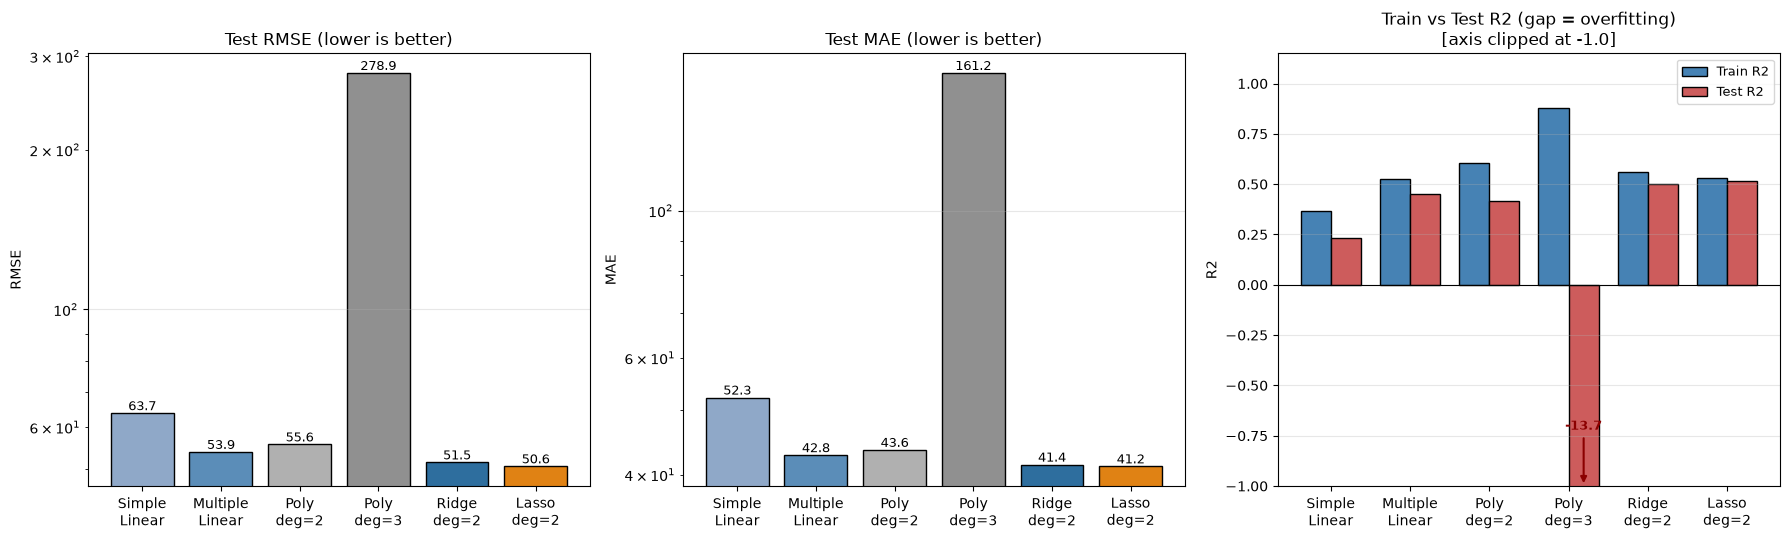

In [42]:
# Visual comparison of the metrics
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
short_names = ['Simple\nLinear', 'Multiple\nLinear', 'Poly\ndeg=2', 'Poly\ndeg=3', 'Ridge\ndeg=2', 'Lasso\ndeg=2']
palette = ['#8FA8C8', '#5B8DB8', '#B0B0B0', '#909090', '#2E6E9E', '#E08214']

bars = axes[0].bar(short_names, comparison['RMSE'], color=palette, edgecolor='black')
axes[0].set_title('Test RMSE (lower is better)')
axes[0].set_ylabel('RMSE')
axes[0].set_yscale('log')
axes[0].grid(alpha=0.3, axis='y')
for b, v in zip(bars, comparison['RMSE']):
    axes[0].text(b.get_x() + b.get_width() / 2, b.get_height(), f'{v:.1f}',
                 ha='center', va='bottom', fontsize=9)

bars = axes[1].bar(short_names, comparison['MAE'], color=palette, edgecolor='black')
axes[1].set_title('Test MAE (lower is better)')
axes[1].set_ylabel('MAE')
axes[1].set_yscale('log')
axes[1].grid(alpha=0.3, axis='y')
for b, v in zip(bars, comparison['MAE']):
    axes[1].text(b.get_x() + b.get_width() / 2, b.get_height(), f'{v:.1f}',
                 ha='center', va='bottom', fontsize=9)

width = 0.38
pos = np.arange(len(short_names))
axes[2].bar(pos - width / 2, overfit_df['Train R2'], width, label='Train R2',
            color='steelblue', edgecolor='black')
axes[2].bar(pos + width / 2, overfit_df['Test R2'], width, label='Test R2',
            color='indianred', edgecolor='black')
axes[2].axhline(0, color='black', linewidth=0.8)
axes[2].set_xticks(pos)
axes[2].set_xticklabels(short_names)
# Clip the axis: the degree-3 test R2 of -13.7 would flatten every other bar
axes[2].set_ylim(-1.0, 1.15)
for i, v in enumerate(overfit_df['Test R2']):
    if v < -1.0:
        axes[2].annotate(f'{v:.1f}', xy=(pos[i] + width / 2, -1.0),
                         xytext=(pos[i] + width / 2, -0.72), ha='center', fontsize=9,
                         color='darkred', fontweight='bold',
                         arrowprops=dict(arrowstyle='-|>', color='darkred', lw=1.5))
axes[2].set_title('Train vs Test R2 (gap = overfitting)\n[axis clipped at -1.0]')
axes[2].set_ylabel('R2')
axes[2].legend(loc='upper right', fontsize=9)
axes[2].grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('model_comparison.png', dpi=120, bbox_inches='tight')
plt.show()

In [43]:
best = comparison.loc[comparison['RMSE'].idxmin()]
print(f"Best model by test RMSE: {best['Model']}")
print(f"  MAE = {best['MAE']:.4f} | MSE = {best['MSE']:.4f} | RMSE = {best['RMSE']:.4f} | R2 = {best['R2']:.4f}")

Best model by test RMSE: Lasso deg=2 (alpha=2.98)
  MAE = 41.1625 | MSE = 2560.4197 | RMSE = 50.6006 | R2 = 0.5167


## Analysis and Conclusions

### How well did each model perform?

Ranked by test RMSE (lower is better):

| Rank | Model | MAE | RMSE | Test R2 |
|---|---|---|---|---|
| 1 | Lasso, degree 2 (alpha = 2.98) | 41.16 | **50.60** | **0.517** |
| 2 | Ridge, degree 2 (alpha = 92.5) | 41.41 | 51.47 | 0.500 |
| 3 | Multiple Linear (10 features) | 42.79 | 53.85 | 0.453 |
| 4 | Polynomial degree 2, unregularized | 43.58 | 55.64 | 0.416 |
| 5 | Simple Linear (bmi only) | 52.26 | 63.73 | 0.233 |
| 6 | Polynomial degree 3, unregularized | 161.19 | 278.94 | -13.686 |

- **Simple Linear Regression (BMI only)** is the weakest sensible model, explaining just 23% of the test variance. It confirms BMI genuinely carries signal, but one predictor cannot span the full range of the target, so the predicted-vs-actual plot collapses into a narrow band. It clearly **underfits**.
- **Multiple Regression (all 10 features)** roughly doubles the explained variance and cuts RMSE by 10 units. Its train-test R2 gap is a healthy 0.075. This is a strong result for how simple the model is.
- **Unregularized Polynomial Regression** hurt at every degree tested. Degree 2 fits the training data better but generalizes *worse* than plain linear regression; degree 3 collapses to a test R2 of -13.7. With 353 training samples, 285 polynomial features is far too much capacity.
- **Ridge and Lasso** on the degree-2 features are the two best models in the lab. Crucially they do not merely undo the overfitting - they surpass plain multiple regression, with Lasso reaching R2 = 0.517 versus 0.453. The degree-2 interaction terms *do* contain usable signal; only regularization could extract it without also absorbing the noise.

### Which models handled overfitting?

The train-vs-test R2 table is the clearest evidence:

| Model | Train R2 | Test R2 | Gap |
|---|---|---|---|
| Simple Linear (bmi) | 0.366 | 0.233 | 0.132 |
| Multiple Linear | 0.528 | 0.453 | 0.075 |
| Polynomial degree 2 | 0.606 | 0.416 | 0.191 |
| Polynomial degree 3 | 0.877 | -13.686 | 14.563 |
| Ridge degree 2 | 0.563 | 0.500 | 0.063 |
| Lasso degree 2 | 0.531 | 0.517 | **0.015** |

The unregularized polynomial models show the damage: degree 2 nearly triples the gap of the linear model, and degree 3 blows it out to 14.6. Ridge and Lasso, working on the *same* degree-2 feature space, cut the gap from 0.191 down to 0.063 and 0.015 respectively - while simultaneously raising test accuracy. Lasso ends up the least overfit model in the entire lab, which is remarkable given it started from a 65-feature design matrix.

Note that both regularized models have *lower* training R2 than the unregularized degree-2 model (0.563 and 0.531 vs 0.606). Deliberately fitting the training data worse in exchange for better generalization is precisely the bias-variance trade-off in action.

Cross-validated alpha selection mattered here methodologically. Picking alpha off the test curve would leak information: the test-optimal values were alpha = 26.5 (Ridge) and 2.18 (Lasso), whereas 5-fold CV on the training set chose 92.5 and 2.98. Alpha was chosen using training data only, and the test set was scored exactly once per model, so the reported numbers are honest estimates of generalization.

### Insights about the Diabetes dataset

1. **The relationship is close to linear, but not purely additive.** No unregularized polynomial model beat the plain 10-feature fit, which suggests a mostly additive structure. Yet regularized degree-2 models beat it by ~6 points of R2, so a modest amount of genuine interaction/curvature signal exists - it is just small enough that it is swamped by noise unless the coefficients are constrained.
2. **BMI and the serum measurement `s5` are the dominant predictors.** They lead the raw correlation ranking (0.59 and 0.57) and hold the two largest coefficients that survive Lasso selection (24.1 and 19.6), with `bp` and `s3` behind them.
3. **The serum features are heavily collinear.** In the unregularized fit `s1` gets a coefficient of -931 despite having a *positive* raw correlation with the target - the model is using it to cancel variance shared with `s2` and `s5`. Ridge visibly stabilizes this, and Lasso removes `s1`, `s2` and `s4` from the model entirely.
4. **There is a hard ceiling on accuracy.** The best model still leaves ~48% of the variance unexplained, with a typical error of ~50 units against a target standard deviation of 77. Disease progression clearly depends on factors this dataset does not measure, so no amount of model complexity will close that gap - which is exactly why the high-degree models could only overfit.
5. **Small n is the binding constraint.** With 442 total samples, model capacity has to be spent carefully. This dataset is a compact, honest demonstration of why regularization exists.

### Summary

On the Diabetes dataset, **Lasso regression on degree-2 polynomial features is the best model**, achieving the lowest MAE, MSE and RMSE and the highest R2 (0.517) while also being the least overfit and, at 16 active terms out of 65, the most interpretable of the polynomial models. Ridge is a close second.

The broader lesson is that the two ingredients had to be combined. Polynomial expansion alone made things worse; regularization applied to a model that was not overfitting would have added nothing. It was expanding the feature space *and then* constraining it that produced the winning model. Between the two penalties, Lasso is preferable here for interpretability and feature selection, while Ridge is the safer choice if the correlated serum measurements should all be retained rather than having the group arbitrarily pruned.